shape: (420551, 15)
from: 2009-01-01 00:10:00  to: 2017-01-01 00:00:00

columns: ['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']

missing per column:
 Date Time          0
p (mbar)           0
T (degC)           0
Tpot (K)           0
Tdew (degC)        0
rh (%)             0
VPmax (mbar)       0
VPact (mbar)       0
VPdef (mbar)       0
sh (g/kg)          0
H2OC (mmol/mol)    0
rho (g/m**3)       0
wv (m/s)           0
max. wv (m/s)      0
wd (deg)           0

             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  rho (g/m**3)  wv (m/s)  max. wv (m/s)  wd (deg)
0 2009-01-01 00:10:00    996.52     -8.02    265.40        -8.90    93.3          3.33          3.11          0.22       1.94             3.12       1307.75      1.03          

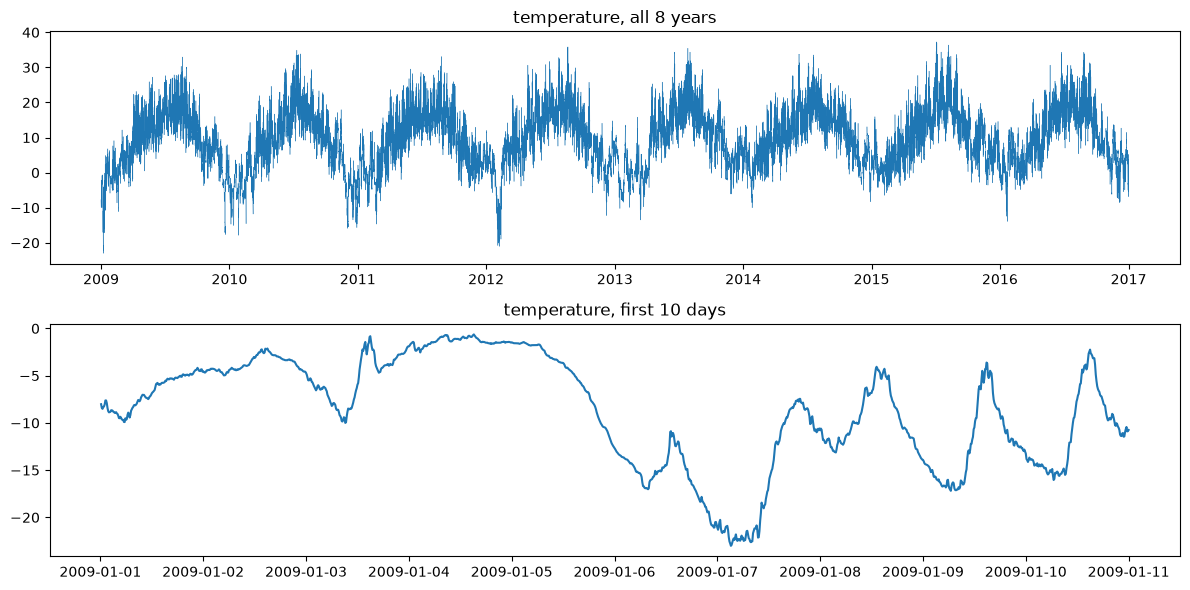

In [1]:
import os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
zip_path = "./data/jena_climate.zip"
csv_path = "./data/jena_climate_2009_2016.csv"

os.makedirs("./data", exist_ok=True)
if not os.path.exists(csv_path):
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("./data")

df = pd.read_csv(csv_path)
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")

print("shape:", df.shape)
print("from:", df["Date Time"].min(), " to:", df["Date Time"].max())
print("\ncolumns:", list(df.columns))
print("\nmissing per column:\n", df.isna().sum().to_string())
print("\n", df.head(3).to_string())

T = df["T (degC)"]
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(df["Date Time"], T, lw=0.3)
axes[0].set_title("temperature, all 8 years")
axes[1].plot(df["Date Time"][:1440], T[:1440])
axes[1].set_title("temperature, first 10 days")
plt.tight_layout()
plt.show()

In [2]:
print(df.describe().T[["min", "mean", "max"]].to_string())

dt = df["Date Time"].diff().dropna()
print("\ntime steps:\n", dt.value_counts().head(5).to_string())
print("\nduplicate timestamps:", df["Date Time"].duplicated().sum())

                                 min                        mean                  max
Date Time        2009-01-01 00:10:00  2012-12-30 06:26:51.498724  2017-01-01 00:00:00
p (mbar)                       913.6                  989.212776              1015.35
T (degC)                      -23.01                    9.450147                37.28
Tpot (K)                       250.6                  283.492743               311.34
Tdew (degC)                   -25.01                    4.955854                23.11
rh (%)                         12.95                   76.008259                100.0
VPmax (mbar)                    0.95                   13.576251                63.77
VPact (mbar)                    0.79                    9.533756                28.32
VPdef (mbar)                     0.0                    4.042412                46.01
sh (g/kg)                        0.5                    6.022408                18.13
H2OC (mmol/mol)                  0.8                  

In [3]:
bad = df["wv (m/s)"] == -9999
print("wv -9999 count:", bad.sum())
print("max. wv -9999 count:", (df["max. wv (m/s)"] == -9999).sum())
i = np.where(bad)[0][0]
print("\nfirst -9999 with neighbors:\n", df.iloc[i-2:i+3][["Date Time", "T (degC)", "wv (m/s)", "max. wv (m/s)"]].to_string())

dup = df[df["Date Time"].duplicated(keep=False)].sort_values("Date Time")
print("\nduplicate rows:", len(dup))
same = dup.groupby("Date Time").nunique().drop(columns=[], errors="ignore").max(axis=1).eq(1).mean()
print("share of duplicated timestamps with identical rows:", round(same, 3))

back = np.where(df["Date Time"].diff() < pd.Timedelta(0))[0]
for j in back:
    print(f"\nbackward jump at row {j}:")
    print(df.iloc[j-2:j+3][["Date Time", "T (degC)"]].to_string())

wv -9999 count: 18
max. wv -9999 count: 20

first -9999 with neighbors:
                  Date Time  T (degC)  wv (m/s)  max. wv (m/s)
343576 2015-07-13 08:50:00     16.88      2.63           5.22
343577 2015-07-13 09:00:00     16.98      6.16       -9999.00
343578 2015-07-13 09:10:00     16.85  -9999.00       -9999.00
343579 2015-07-13 09:20:00     17.06  -9999.00       -9999.00
343580 2015-07-13 09:30:00     17.43  -9999.00       -9999.00

duplicate rows: 654
share of duplicated timestamps with identical rows: 1.0

backward jump at row 78766:
                Date Time  T (degC)
78764 2010-07-01 23:50:00     20.22
78765 2010-07-02 00:00:00     19.89
78766 2010-07-01 00:10:00     17.87
78767 2010-07-01 00:20:00     17.82
78768 2010-07-01 00:30:00     17.92

backward jump at row 274565:
                 Date Time  T (degC)
274563 2014-03-21 17:10:00     18.01
274564 2014-03-21 17:20:00     17.82
274565 2014-03-20 11:00:00     15.63
274566 2014-03-20 11:10:00     16.20
274567 2014-03-20 

In [4]:
n_before = len(df)
df = df.drop_duplicates().sort_values("Date Time").reset_index(drop=True)
print("rows before:", n_before, "| after:", len(df), "| removed:", n_before - len(df))

dt = df["Date Time"].diff().dropna()
print("\ntime steps:\n", dt.value_counts().to_string())
print("\nduplicate timestamps:", df["Date Time"].duplicated().sum())

for col in ["wv (m/s)", "max. wv (m/s)"]:
    bad = (df[col] == -9999).values
    print(f"\n{col} | -9999 count after dedup: {bad.sum()}")
    run_id = np.cumsum(np.diff(np.concatenate([[0], bad.astype(int)])) == 1)
    for r in np.unique(run_id[bad]):
        idx = np.where(bad & (run_id == r))[0]
        print(f"  run from {df['Date Time'][idx[0]]} to {df['Date Time'][idx[-1]]} | {len(idx)} readings")

rows before: 420551 | after: 420224 | removed: 327

time steps:
 Date Time
0 days 00:10:00    420218
0 days 00:20:00         2
0 days 00:30:00         1
0 days 16:00:00         1
3 days 02:20:00         1

duplicate timestamps: 0

wv (m/s) | -9999 count after dedup: 18
  run from 2015-07-13 09:10:00 to 2015-07-13 12:00:00 | 18 readings

max. wv (m/s) | -9999 count after dedup: 20
  run from 2015-07-13 09:00:00 to 2015-07-13 12:10:00 | 20 readings


In [5]:
gaps = df["Date Time"].diff()
big = np.where(gaps > pd.Timedelta(minutes=10))[0]
for j in big:
    print(f"gap of {gaps[j]} between {df['Date Time'][j-1]} and {df['Date Time'][j]}")

gap of 0 days 00:30:00 between 2009-10-08 09:40:00 and 2009-10-08 10:10:00
gap of 0 days 00:20:00 between 2013-05-16 08:50:00 and 2013-05-16 09:10:00
gap of 0 days 00:20:00 between 2014-07-30 08:00:00 and 2014-07-30 08:20:00
gap of 0 days 16:00:00 between 2014-09-24 17:00:00 and 2014-09-25 09:00:00
gap of 3 days 02:20:00 between 2016-10-25 10:30:00 and 2016-10-28 12:50:00


In [6]:
seg_break = df["Date Time"].diff() > pd.Timedelta(minutes=30)
df["segment"] = seg_break.cumsum()

parts = []
for s, g in df.groupby("segment"):
    g = g.set_index("Date Time")
    full = pd.date_range(g.index[0], g.index[-1], freq="10min")
    g = g.reindex(full)
    n_filled = g["T (degC)"].isna().sum()
    g = g.interpolate(method="time")
    g["segment"] = s
    parts.append(g)
    print(f"segment {s} | {g.index[0]} -> {g.index[-1]} | {len(g)} readings | filled {n_filled}")

df = pd.concat(parts).rename_axis("Date Time").reset_index()

steps = df.groupby("segment")["Date Time"].diff().dropna().value_counts()
print("\ntime steps inside segments:\n", steps.to_string())
print("total rows:", len(df))

segment 0 | 2009-01-01 00:10:00 -> 2014-09-24 17:00:00 | 301350 readings | filled 4
segment 1 | 2014-09-25 09:00:00 -> 2016-10-25 10:30:00 | 109594 readings | filled 0
segment 2 | 2016-10-28 12:50:00 -> 2017-01-01 00:00:00 | 9284 readings | filled 0

time steps inside segments:
 Date Time
0 days 00:10:00    420225
total rows: 420228


In [7]:
train = df[df["Date Time"].dt.year <= 2014]

parts = []
for s, g in train.groupby("segment"):
    h = g.set_index("Date Time").resample("1h").mean(numeric_only=True)
    h["segment"] = s
    parts.append(h)
hourly = pd.concat(parts)

grp = hourly.groupby("segment")
dT_future = grp["T (degC)"].shift(-24) - hourly["T (degC)"]

print(f"{'past hours':>10} | {'corr(dp_past, dT_next24h)':>26}")
for k in [3, 6, 12, 24, 36, 48, 72, 96, 120, 168]:
    dp_past = hourly["p (mbar)"] - grp["p (mbar)"].shift(k)
    print(f"{k:>10} | {dp_past.corr(dT_future):>26.3f}")

past hours |  corr(dp_past, dT_next24h)
         3 |                     -0.006
         6 |                      0.027
        12 |                      0.077
        24 |                      0.143
        36 |                      0.175
        48 |                      0.181
        72 |                      0.155
        96 |                      0.138
       120 |                      0.120
       168 |                      0.122


In [8]:
train = df[df["Date Time"].dt.year <= 2014].copy()
rad = np.deg2rad(train["wd (deg)"])
train["wx"] = train["wv (m/s)"] * np.cos(rad)
train["wy"] = train["wv (m/s)"] * np.sin(rad)

parts = []
for s, g in train.groupby("segment"):
    h = g.set_index("Date Time").resample("1h").mean(numeric_only=True)
    h["segment"] = s
    parts.append(h)
hourly = pd.concat(parts)

grp = hourly.groupby("segment")
dT_future = grp["T (degC)"].shift(-24) - hourly["T (degC)"]

cols = ["T (degC)", "p (mbar)", "rh (%)", "Tdew (degC)", "wv (m/s)", "wx", "wy"]
lags = [3, 6, 12, 24, 36, 48, 72, 96, 120, 168]

table = pd.DataFrame(index=lags, columns=[c.split(" ")[0] for c in cols], dtype=float)
for c in cols:
    for k in lags:
        d_past = hourly[c] - grp[c].shift(k)
        table.loc[k, c.split(" ")[0]] = d_past.corr(dT_future)

table.index.name = "past hours"
print(table.round(3).to_string())

                T      p     rh   Tdew     wv     wx     wy
past hours                                                 
3          -0.045 -0.006  0.072  0.038 -0.028 -0.039  0.052
6          -0.079  0.027  0.091  0.004 -0.040 -0.044  0.062
12         -0.107  0.077  0.097 -0.044 -0.061 -0.041  0.071
24         -0.149  0.143  0.097 -0.080 -0.093 -0.023  0.118
36         -0.139  0.175  0.096 -0.099 -0.093 -0.026  0.081
48         -0.204  0.181  0.116 -0.123 -0.113 -0.011  0.084
72         -0.249  0.155  0.132 -0.161 -0.120  0.000  0.070
96         -0.274  0.138  0.149 -0.180 -0.121  0.004  0.060
120        -0.263  0.120  0.143 -0.175 -0.117 -0.014  0.046
168        -0.242  0.122  0.117 -0.175 -0.099 -0.011  0.041


In [9]:
import importlib, jena_pipeline as jp
importlib.reload(jp)

raw = jp.load_raw("./data/jena_climate_2009_2016.csv")
hourly = jp.to_hourly(jp.clean(raw))
tr, va, te = jp.split_by_year(hourly)
mean, std = jp.fit_scaler(tr)

Xtr, ytr, btr = jp.make_windows(tr, mean, std)
Xva, yva, bva = jp.make_windows(va, mean, std)
Xte, yte, bte = jp.make_windows(te, mean, std)

for name, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    print(f"{name:>5} | X {X.shape} | y {y.shape} | NaN {np.isnan(X).sum()}")

mae_base = np.abs(yva - bva).mean()
print(f"\nbaseline on val (same hour yesterday) | MAE {mae_base:.3f} degC")

train | X (52331, 96, 11) | y (52331,) | NaN 0
  val | X (8641, 96, 11) | y (8641,) | NaN 0
 test | X (8473, 96, 11) | y (8473,) | NaN 0

baseline on val (same hour yesterday) | MAE 2.764 degC


In [10]:
import time
import torch
import torch.nn as nn

device = "cuda"
T_mean, T_std = float(mean[jp.TARGET]), float(std[jp.TARGET])

def to_dev(X, y):
    X = torch.tensor(X, device=device)
    y = torch.tensor((y - T_mean) / T_std, dtype=torch.float32, device=device)
    return X, y

Xtr_g, ytr_g = to_dev(Xtr, ytr)
Xva_g, yva_g = to_dev(Xva, yva)

def make_dense():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(96 * 11, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 1),
    )

loss_fn = nn.L1Loss()

def mae_degC(model, X, y, bs=4096):
    model.eval()
    tot = 0.0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out = model(X[i:i+bs]).squeeze(1)
            tot += (out - y[i:i+bs]).abs().sum().item()
    return tot / len(X) * T_std

def train_ts(model, epochs=20, bs=256, lr=1e-3):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    print("params:", sum(p.numel() for p in model.parameters()))
    print(f"baseline val MAE {mae_base:.3f} degC")
    hist = []
    for ep in range(epochs):
        t0 = time.time()
        model.train()
        perm = torch.randperm(len(Xtr_g), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]
            loss = loss_fn(model(Xtr_g[idx]).squeeze(1), ytr_g[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        tr_mae = mae_degC(model, Xtr_g, ytr_g)
        va_mae = mae_degC(model, Xva_g, yva_g)
        hist.append((tr_mae, va_mae))
        print(f"ep {ep+1:>2} | train MAE {tr_mae:.3f} | val MAE {va_mae:.3f} degC | {time.time()-t0:.1f}s")
    return model, hist

torch.manual_seed(0)
dense, hist_dense = train_ts(make_dense())

params: 69761
baseline val MAE 2.764 degC
ep  1 | train MAE 2.263 | val MAE 2.635 degC | 0.8s
ep  2 | train MAE 2.116 | val MAE 2.621 degC | 0.3s
ep  3 | train MAE 1.927 | val MAE 2.760 degC | 0.3s
ep  4 | train MAE 1.858 | val MAE 2.718 degC | 0.3s
ep  5 | train MAE 1.741 | val MAE 2.854 degC | 0.3s
ep  6 | train MAE 1.721 | val MAE 2.921 degC | 0.3s
ep  7 | train MAE 1.607 | val MAE 2.905 degC | 0.3s
ep  8 | train MAE 1.550 | val MAE 2.944 degC | 0.3s
ep  9 | train MAE 1.485 | val MAE 2.914 degC | 0.3s
ep 10 | train MAE 1.513 | val MAE 2.956 degC | 0.3s
ep 11 | train MAE 1.422 | val MAE 2.975 degC | 0.4s
ep 12 | train MAE 1.402 | val MAE 2.986 degC | 0.3s
ep 13 | train MAE 1.410 | val MAE 3.002 degC | 0.3s
ep 14 | train MAE 1.335 | val MAE 2.987 degC | 0.3s
ep 15 | train MAE 1.311 | val MAE 3.076 degC | 0.3s
ep 16 | train MAE 1.333 | val MAE 3.056 degC | 0.3s
ep 17 | train MAE 1.334 | val MAE 2.993 degC | 0.3s
ep 18 | train MAE 1.293 | val MAE 3.004 degC | 0.3s
ep 19 | train MAE 1.25

In [11]:
class SimpleRNN(nn.Module):
    def __init__(self, n_features=11, hidden=32):
        super().__init__()
        self.rnn = nn.RNN(input_size=n_features, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, h_last = self.rnn(x)
        return self.head(h_last[-1])

torch.manual_seed(0)
rnn, hist_rnn = train_ts(SimpleRNN())

params: 1473
baseline val MAE 2.764 degC
ep  1 | train MAE 2.458 | val MAE 2.641 degC | 0.5s
ep  2 | train MAE 2.426 | val MAE 2.614 degC | 0.4s
ep  3 | train MAE 2.384 | val MAE 2.576 degC | 0.4s
ep  4 | train MAE 2.376 | val MAE 2.554 degC | 0.4s
ep  5 | train MAE 2.346 | val MAE 2.553 degC | 0.4s
ep  6 | train MAE 2.339 | val MAE 2.548 degC | 0.4s
ep  7 | train MAE 2.319 | val MAE 2.556 degC | 0.4s
ep  8 | train MAE 2.298 | val MAE 2.545 degC | 0.4s
ep  9 | train MAE 2.356 | val MAE 2.605 degC | 0.4s
ep 10 | train MAE 2.302 | val MAE 2.560 degC | 0.4s
ep 11 | train MAE 2.333 | val MAE 2.585 degC | 0.4s
ep 12 | train MAE 2.342 | val MAE 2.623 degC | 0.4s
ep 13 | train MAE 2.296 | val MAE 2.574 degC | 0.4s
ep 14 | train MAE 2.275 | val MAE 2.562 degC | 0.4s
ep 15 | train MAE 2.274 | val MAE 2.553 degC | 0.4s
ep 16 | train MAE 2.314 | val MAE 2.605 degC | 0.4s
ep 17 | train MAE 2.265 | val MAE 2.585 degC | 0.4s
ep 18 | train MAE 2.268 | val MAE 2.561 degC | 0.4s
ep 19 | train MAE 2.242

hours back | grad (relative to last hour)
         1 | 1.00e+00
         2 | 2.49e-01
         3 | 2.00e-01
         6 | 4.19e-02
        12 | 1.54e-02
        24 | 4.72e-03
        48 | 3.44e-04
        72 | 9.93e-06
        96 | 4.99e-07


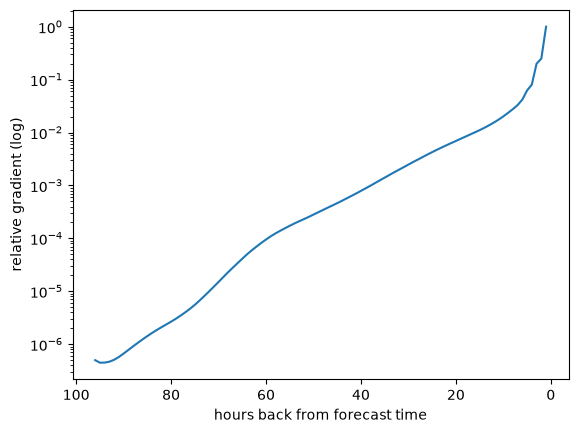

In [12]:
rnn.train()
X = Xva_g[:2000].clone().requires_grad_(True)
loss = loss_fn(rnn(X).squeeze(1), yva_g[:2000])
loss.backward()

g = X.grad.abs().mean(dim=(0, 2)).cpu().numpy()
g = g / g[-1]

print(f"{'hours back':>10} | grad (relative to last hour)")
for back in [1, 2, 3, 6, 12, 24, 48, 72, 96]:
    print(f"{back:>10} | {g[-back]:.2e}")

import matplotlib.pyplot as plt
plt.semilogy(range(96, 0, -1), g)
plt.gca().invert_xaxis()
plt.xlabel("hours back from forecast time"); plt.ylabel("relative gradient (log)")
plt.show()

In [13]:
class RecurrentRegressor(nn.Module):
    def __init__(self, cell="rnn", n_features=11, hidden=32):
        super().__init__()
        layers = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}
        self.rnn = layers[cell](input_size=n_features, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])

results = {"rnn_32": (rnn, hist_rnn)}

for name, cell, hidden in [("lstm_32", "lstm", 32), ("rnn_68", "rnn", 68)]:
    torch.manual_seed(0)
    model, hist = train_ts(RecurrentRegressor(cell, hidden=hidden))
    results[name] = (model, hist)

print(f"\n{'model':>8} | {'params':>6} | {'best val':>8} | {'@ep':>3} | {'last train':>10}")
for name, (model, hist) in results.items():
    va = [h[1] for h in hist]
    best = int(np.argmin(va))
    n_par = sum(p.numel() for p in model.parameters())
    print(f"{name:>8} | {n_par:>6} | {va[best]:>8.3f} | {best+1:>3} | {hist[-1][0]:>10.3f}")

params: 5793
baseline val MAE 2.764 degC
ep  1 | train MAE 2.423 | val MAE 2.659 degC | 0.8s
ep  2 | train MAE 2.376 | val MAE 2.628 degC | 0.5s
ep  3 | train MAE 2.306 | val MAE 2.600 degC | 0.5s
ep  4 | train MAE 2.263 | val MAE 2.596 degC | 0.5s
ep  5 | train MAE 2.266 | val MAE 2.578 degC | 0.5s
ep  6 | train MAE 2.220 | val MAE 2.600 degC | 0.5s
ep  7 | train MAE 2.205 | val MAE 2.554 degC | 0.5s
ep  8 | train MAE 2.220 | val MAE 2.616 degC | 0.5s
ep  9 | train MAE 2.195 | val MAE 2.595 degC | 0.5s
ep 10 | train MAE 2.156 | val MAE 2.747 degC | 0.5s
ep 11 | train MAE 2.159 | val MAE 2.656 degC | 0.5s
ep 12 | train MAE 2.091 | val MAE 2.792 degC | 0.6s
ep 13 | train MAE 2.082 | val MAE 2.704 degC | 0.6s
ep 14 | train MAE 2.045 | val MAE 2.692 degC | 0.5s
ep 15 | train MAE 2.021 | val MAE 2.752 degC | 0.6s
ep 16 | train MAE 2.004 | val MAE 2.806 degC | 0.5s
ep 17 | train MAE 2.001 | val MAE 2.865 degC | 0.5s
ep 18 | train MAE 1.997 | val MAE 2.832 degC | 0.5s
ep 19 | train MAE 1.971

hours back |   rnn_32 |  lstm_32 |   rnn_68
         1 |  1.0e+00 |  1.0e+00 |  1.0e+00
         6 |  4.2e-02 |  1.6e-01 |  6.9e-02
        24 |  4.7e-03 |  8.1e-02 |  5.2e-03
        48 |  3.4e-04 |  4.4e-02 |  1.9e-04
        72 |  9.9e-06 |  3.0e-02 |  1.1e-05
        96 |  5.0e-07 |  3.2e-02 |  4.2e-07


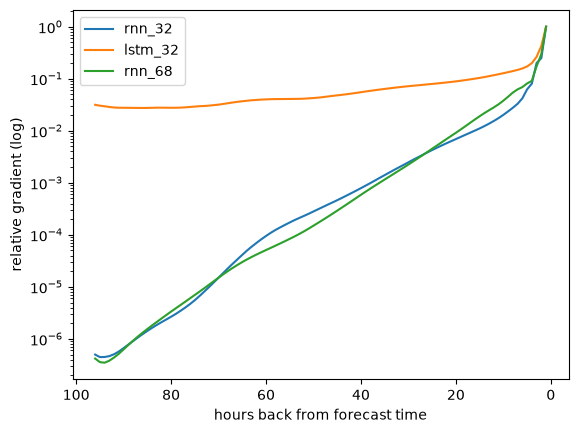

In [14]:
def grad_over_time(model, X, y):
    model.train()
    X = X.clone().requires_grad_(True)
    loss = loss_fn(model(X).squeeze(1), y)
    loss.backward()
    g = X.grad.abs().mean(dim=(0, 2)).cpu().numpy()
    model.zero_grad()
    return g / g[-1]

grads = {name: grad_over_time(m, Xva_g[:2000], yva_g[:2000]) for name, (m, _) in results.items()}

backs = [1, 6, 24, 48, 72, 96]
print(f"{'hours back':>10} | " + " | ".join(f"{n:>8}" for n in grads))
for b in backs:
    print(f"{b:>10} | " + " | ".join(f"{g[-b]:>8.1e}" for g in grads.values()))

for name, g in grads.items():
    plt.semilogy(range(96, 0, -1), g, label=name)
plt.gca().invert_xaxis()
plt.xlabel("hours back from forecast time"); plt.ylabel("relative gradient (log)")
plt.legend(); plt.show()

params: 5793
init ||W|| 7.73
ep  1 | train 2.423 | val 2.659 | ||W|| 8.67
ep  2 | train 2.376 | val 2.628 | ||W|| 8.95
ep  3 | train 2.306 | val 2.600 | ||W|| 9.24
ep  4 | train 2.263 | val 2.596 | ||W|| 9.44
ep  5 | train 2.266 | val 2.578 | ||W|| 9.73
ep  6 | train 2.220 | val 2.600 | ||W|| 9.93
ep  7 | train 2.205 | val 2.554 | ||W|| 10.12
ep  8 | train 2.220 | val 2.616 | ||W|| 10.38
ep  9 | train 2.195 | val 2.595 | ||W|| 10.59
ep 10 | train 2.156 | val 2.747 | ||W|| 10.80
ep 11 | train 2.159 | val 2.656 | ||W|| 11.01
ep 12 | train 2.091 | val 2.792 | ||W|| 11.23
ep 13 | train 2.082 | val 2.704 | ||W|| 11.45
ep 14 | train 2.045 | val 2.692 | ||W|| 11.63
ep 15 | train 2.021 | val 2.752 | ||W|| 11.84
ep 16 | train 2.004 | val 2.806 | ||W|| 12.05
ep 17 | train 2.001 | val 2.865 | ||W|| 12.25
ep 18 | train 1.997 | val 2.832 | ||W|| 12.43
ep 19 | train 1.971 | val 2.848 | ||W|| 12.62
ep 20 | train 1.930 | val 2.892 | ||W|| 12.84
params: 5577
init ||W|| 5.20
ep  1 | train 2.476 | val 2.

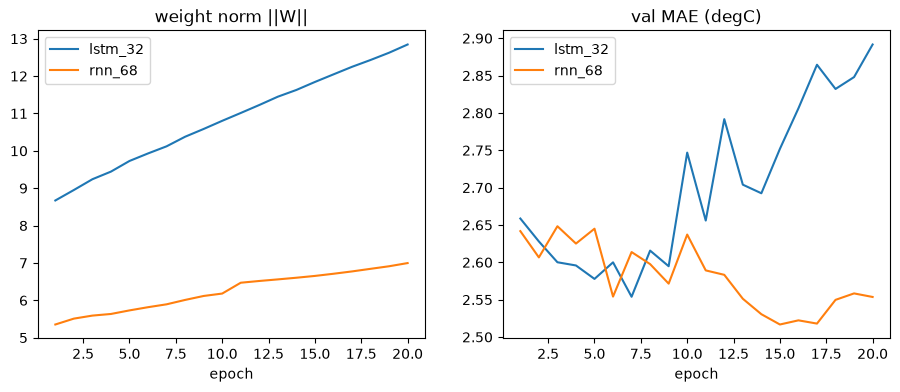

In [15]:
def weight_norm(model):
    return torch.sqrt(sum((p.detach() ** 2).sum() for p in model.parameters())).item()

def train_ts(model, epochs=20, bs=256, lr=1e-3):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    print("params:", sum(p.numel() for p in model.parameters()))
    print(f"init ||W|| {weight_norm(model):.2f}")
    hist = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_g), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]
            loss = loss_fn(model(Xtr_g[idx]).squeeze(1), ytr_g[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        tr_mae = mae_degC(model, Xtr_g, ytr_g)
        va_mae = mae_degC(model, Xva_g, yva_g)
        norm = weight_norm(model)
        hist.append((tr_mae, va_mae, norm))
        print(f"ep {ep+1:>2} | train {tr_mae:.3f} | val {va_mae:.3f} | ||W|| {norm:.2f}")
    return model, hist

norm_runs = {}
for name, cell, hidden in [("lstm_32", "lstm", 32), ("rnn_68", "rnn", 68)]:
    torch.manual_seed(0)
    _, hist = train_ts(RecurrentRegressor(cell, hidden=hidden))
    norm_runs[name] = hist

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for name, hist in norm_runs.items():
    ep = range(1, len(hist) + 1)
    a1.plot(ep, [h[2] for h in hist], label=name)
    a2.plot(ep, [h[1] for h in hist], label=name)
a1.set_title("weight norm ||W||"); a2.set_title("val MAE (degC)")
for a in (a1, a2):
    a.set_xlabel("epoch"); a.legend()
plt.show()

params: 5793
init ||W|| 7.73
ep  1 | train 2.454 | val 2.685 | ||W|| 8.59
ep  2 | train 2.390 | val 2.639 | ||W|| 8.85
ep  3 | train 2.357 | val 2.596 | ||W|| 9.06
ep  4 | train 2.330 | val 2.603 | ||W|| 9.23
ep  5 | train 2.311 | val 2.627 | ||W|| 9.41
ep  6 | train 2.292 | val 2.552 | ||W|| 9.58
ep  7 | train 2.263 | val 2.566 | ||W|| 9.78
ep  8 | train 2.234 | val 2.547 | ||W|| 9.98
ep  9 | train 2.325 | val 2.623 | ||W|| 10.17
ep 10 | train 2.236 | val 2.614 | ||W|| 10.35
ep 11 | train 2.185 | val 2.634 | ||W|| 10.53
ep 12 | train 2.172 | val 2.604 | ||W|| 10.70
ep 13 | train 2.179 | val 2.602 | ||W|| 10.87
ep 14 | train 2.162 | val 2.622 | ||W|| 11.06
ep 15 | train 2.163 | val 2.581 | ||W|| 11.22
ep 16 | train 2.165 | val 2.633 | ||W|| 11.37
ep 17 | train 2.119 | val 2.636 | ||W|| 11.54
ep 18 | train 2.124 | val 2.606 | ||W|| 11.69
ep 19 | train 2.112 | val 2.630 | ||W|| 11.84
ep 20 | train 2.102 | val 2.575 | ||W|| 11.99


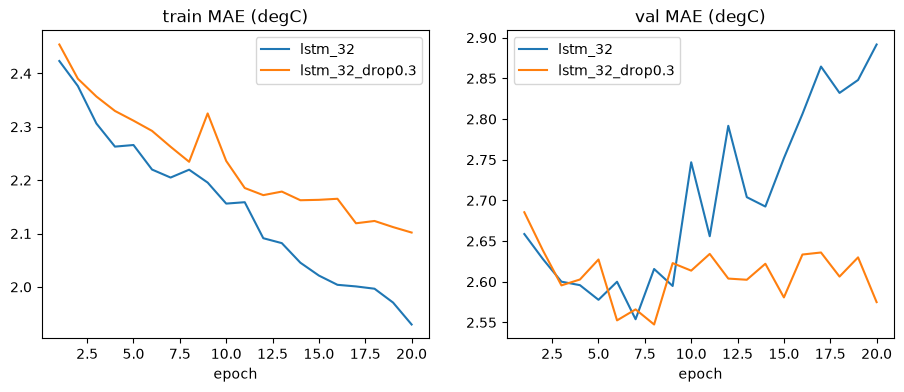


           model | best val | @ep | last train | last val
         lstm_32 |    2.554 |   7 |      1.930 |    2.892
 lstm_32_drop0.3 |    2.547 |   8 |      2.102 |    2.575


In [16]:
class RecurrentRegressor(nn.Module):
    def __init__(self, cell="rnn", n_features=11, hidden=32, p_drop=0.0):
        super().__init__()
        layers = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}
        self.rnn = layers[cell](input_size=n_features, hidden_size=hidden, batch_first=True)
        self.drop = nn.Dropout(p_drop)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(self.drop(out[:, -1]))

torch.manual_seed(0)
_, hist_do = train_ts(RecurrentRegressor("lstm", hidden=32, p_drop=0.3))

runs = {"lstm_32": norm_runs["lstm_32"], "lstm_32_drop0.3": hist_do}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for name, hist in runs.items():
    ep = range(1, len(hist) + 1)
    a1.plot(ep, [h[0] for h in hist], label=name)
    a2.plot(ep, [h[1] for h in hist], label=name)
a1.set_title("train MAE (degC)"); a2.set_title("val MAE (degC)")
for a in (a1, a2):
    a.set_xlabel("epoch"); a.legend()
plt.show()

print(f"\n{'model':>16} | {'best val':>8} | {'@ep':>3} | {'last train':>10} | {'last val':>8}")
for name, hist in runs.items():
    va = [h[1] for h in hist]
    best = int(np.argmin(va))
    print(f"{name:>16} | {va[best]:>8.3f} | {best+1:>3} | {hist[-1][0]:>10.3f} | {va[-1]:>8.3f}")

In [17]:
mae_base_tr = np.abs(ytr - btr).mean()
mae_base_va = np.abs(yva - bva).mean()

print(f"baseline train years | MAE {mae_base_tr:.3f} degC")
print(f"baseline val year    | MAE {mae_base_va:.3f} degC")
print(f"ratio val / train    | {mae_base_va / mae_base_tr:.3f}")

baseline train years | MAE 2.595 degC
baseline val year    | MAE 2.764 degC
ratio val / train    | 1.065


params: 4353
init ||W|| 6.69
ep  1 | train 2.460 | val 2.675 | ||W|| 7.24
ep  2 | train 2.420 | val 2.644 | ||W|| 7.78
ep  3 | train 2.369 | val 2.580 | ||W|| 8.40
ep  4 | train 2.320 | val 2.524 | ||W|| 8.86
ep  5 | train 2.305 | val 2.554 | ||W|| 9.27
ep  6 | train 2.271 | val 2.527 | ||W|| 9.61
ep  7 | train 2.254 | val 2.501 | ||W|| 9.91
ep  8 | train 2.254 | val 2.506 | ||W|| 10.23
ep  9 | train 2.224 | val 2.484 | ||W|| 10.54
ep 10 | train 2.226 | val 2.483 | ||W|| 10.89
ep 11 | train 2.205 | val 2.471 | ||W|| 11.17
ep 12 | train 2.197 | val 2.493 | ||W|| 11.45
ep 13 | train 2.197 | val 2.479 | ||W|| 11.72
ep 14 | train 2.187 | val 2.477 | ||W|| 11.99
ep 15 | train 2.180 | val 2.492 | ||W|| 12.25
ep 16 | train 2.179 | val 2.495 | ||W|| 12.49
ep 17 | train 2.168 | val 2.487 | ||W|| 12.74
ep 18 | train 2.155 | val 2.469 | ||W|| 12.95
ep 19 | train 2.149 | val 2.488 | ||W|| 13.21
ep 20 | train 2.143 | val 2.476 | ||W|| 13.44

           model | best val | @ep | last train | last val

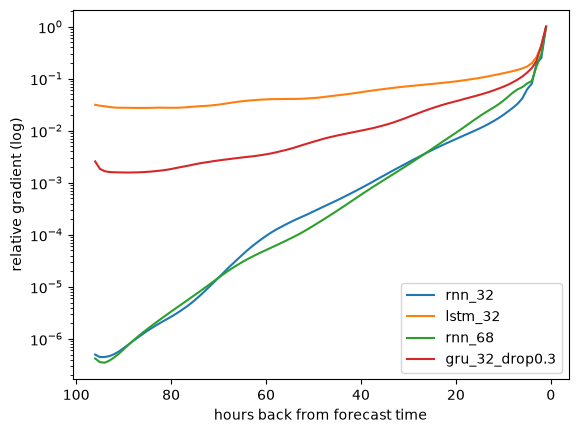

In [18]:
torch.manual_seed(0)
gru_do, hist_gru = train_ts(RecurrentRegressor("gru", hidden=32, p_drop=0.3))
runs["gru_32_drop0.3"] = hist_gru

print(f"\n{'model':>16} | {'best val':>8} | {'@ep':>3} | {'last train':>10} | {'last val':>8}")
for name, hist in runs.items():
    va = [h[1] for h in hist]
    best = int(np.argmin(va))
    print(f"{name:>16} | {va[best]:>8.3f} | {best+1:>3} | {hist[-1][0]:>10.3f} | {va[-1]:>8.3f}")

grads["gru_32_drop0.3"] = grad_over_time(gru_do, Xva_g[:2000], yva_g[:2000])

print(f"\n{'hours back':>10} | " + " | ".join(f"{n:>14}" for n in grads))
for b in [1, 6, 24, 48, 72, 96]:
    print(f"{b:>10} | " + " | ".join(f"{g[-b]:>14.1e}" for g in grads.values()))

for name, g in grads.items():
    plt.semilogy(range(96, 0, -1), g, label=name)
plt.gca().invert_xaxis()
plt.xlabel("hours back from forecast time"); plt.ylabel("relative gradient (log)")
plt.legend(); plt.show()

In [19]:
seeds = [0, 1, 2]
seed_results = {"lstm_32_drop0.3": [], "gru_32_drop0.3": []}

for seed in seeds:
    for name, cell in [("lstm_32_drop0.3", "lstm"), ("gru_32_drop0.3", "gru")]:
        torch.manual_seed(seed)
        _, hist = train_ts(RecurrentRegressor(cell, hidden=32, p_drop=0.3))
        seed_results[name].append(min(h[1] for h in hist))

print(f"\n{'model':>16} | " + " | ".join(f"seed {s}" for s in seeds) + " |  mean |  std")
for name, vals in seed_results.items():
    v = np.array(vals)
    print(f"{name:>16} | " + " | ".join(f"{x:>6.3f}" for x in v) + f" | {v.mean():.3f} | {v.std():.3f}")

params: 5793
init ||W|| 7.73
ep  1 | train 2.454 | val 2.685 | ||W|| 8.59
ep  2 | train 2.390 | val 2.639 | ||W|| 8.85
ep  3 | train 2.357 | val 2.596 | ||W|| 9.06
ep  4 | train 2.330 | val 2.603 | ||W|| 9.23
ep  5 | train 2.311 | val 2.627 | ||W|| 9.41
ep  6 | train 2.292 | val 2.552 | ||W|| 9.58
ep  7 | train 2.263 | val 2.566 | ||W|| 9.78
ep  8 | train 2.234 | val 2.547 | ||W|| 9.98
ep  9 | train 2.325 | val 2.623 | ||W|| 10.17
ep 10 | train 2.236 | val 2.614 | ||W|| 10.35
ep 11 | train 2.185 | val 2.634 | ||W|| 10.53
ep 12 | train 2.172 | val 2.604 | ||W|| 10.70
ep 13 | train 2.179 | val 2.602 | ||W|| 10.87
ep 14 | train 2.162 | val 2.622 | ||W|| 11.06
ep 15 | train 2.163 | val 2.581 | ||W|| 11.22
ep 16 | train 2.165 | val 2.633 | ||W|| 11.37
ep 17 | train 2.119 | val 2.636 | ||W|| 11.54
ep 18 | train 2.124 | val 2.606 | ||W|| 11.69
ep 19 | train 2.112 | val 2.630 | ||W|| 11.84
ep 20 | train 2.102 | val 2.575 | ||W|| 11.99
params: 4353
init ||W|| 6.69
ep  1 | train 2.460 | val 2.67

In [20]:
gru_sizes = {32: seed_results["gru_32_drop0.3"]}

for hidden in [16, 64]:
    gru_sizes[hidden] = []
    for seed in seeds:
        torch.manual_seed(seed)
        _, hist = train_ts(RecurrentRegressor("gru", hidden=hidden, p_drop=0.3))
        gru_sizes[hidden].append(min(h[1] for h in hist))

print(f"\n{'hidden':>6} | {'params':>6} | " + " | ".join(f"seed {s}" for s in seeds) + " |  mean |  std")
for hidden in sorted(gru_sizes):
    v = np.array(gru_sizes[hidden])
    n_par = sum(p.numel() for p in RecurrentRegressor("gru", hidden=hidden).parameters())
    print(f"{hidden:>6} | {n_par:>6} | " + " | ".join(f"{x:>6.3f}" for x in v) + f" | {v.mean():.3f} | {v.std():.3f}")

params: 1409
init ||W|| 5.51
ep  1 | train 2.530 | val 2.760 | ||W|| 5.91
ep  2 | train 2.473 | val 2.720 | ||W|| 6.17
ep  3 | train 2.429 | val 2.658 | ||W|| 6.46
ep  4 | train 2.396 | val 2.632 | ||W|| 6.74
ep  5 | train 2.372 | val 2.616 | ||W|| 7.01
ep  6 | train 2.358 | val 2.592 | ||W|| 7.23
ep  7 | train 2.328 | val 2.561 | ||W|| 7.44
ep  8 | train 2.319 | val 2.567 | ||W|| 7.66
ep  9 | train 2.292 | val 2.518 | ||W|| 7.88
ep 10 | train 2.277 | val 2.525 | ||W|| 8.08
ep 11 | train 2.259 | val 2.502 | ||W|| 8.30
ep 12 | train 2.261 | val 2.519 | ||W|| 8.48
ep 13 | train 2.252 | val 2.486 | ||W|| 8.63
ep 14 | train 2.246 | val 2.510 | ||W|| 8.79
ep 15 | train 2.241 | val 2.511 | ||W|| 8.94
ep 16 | train 2.225 | val 2.479 | ||W|| 9.07
ep 17 | train 2.223 | val 2.477 | ||W|| 9.19
ep 18 | train 2.239 | val 2.482 | ||W|| 9.33
ep 19 | train 2.211 | val 2.473 | ||W|| 9.45
ep 20 | train 2.249 | val 2.532 | ||W|| 9.57
params: 1409
init ||W|| 5.42
ep  1 | train 2.575 | val 2.778 | ||W|| 5.

In [21]:
import copy, os

def train_ts(model, epochs=20, bs=256, lr=1e-3, keep_best=False):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    print("params:", sum(p.numel() for p in model.parameters()))
    hist, best_val, best_state, best_ep = [], float("inf"), None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_g), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]
            loss = loss_fn(model(Xtr_g[idx]).squeeze(1), ytr_g[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        tr_mae = mae_degC(model, Xtr_g, ytr_g)
        va_mae = mae_degC(model, Xva_g, yva_g)
        hist.append((tr_mae, va_mae, weight_norm(model)))
        if keep_best and va_mae < best_val:
            best_val, best_ep = va_mae, ep + 1
            best_state = copy.deepcopy(model.state_dict())
        print(f"ep {ep+1:>2} | train {tr_mae:.3f} | val {va_mae:.3f}")
    if keep_best:
        model.load_state_dict(best_state)
        print(f"restored best epoch {best_ep} | val {best_val:.3f}")
    return model, hist

Xte_g, yte_g = to_dev(Xte, yte)

torch.manual_seed(0)
final, hist_final = train_ts(RecurrentRegressor("gru", hidden=32, p_drop=0.3), keep_best=True)

va_final = mae_degC(final, Xva_g, yva_g)
te_final = mae_degC(final, Xte_g, yte_g)
base_te = np.abs(yte - bte).mean()

print(f"\n{'':>10} | {'val':>6} | {'test':>6}")
print(f"{'baseline':>10} | {mae_base:>6.3f} | {base_te:>6.3f}")
print(f"{'GRU-32':>10} | {va_final:>6.3f} | {te_final:>6.3f}")
print(f"\nimprovement over baseline | val {1 - va_final/mae_base:.1%} | test {1 - te_final/base_te:.1%}")

os.makedirs("models", exist_ok=True)
torch.save({"state_dict": final.state_dict(),
            "config": {"cell": "gru", "hidden": 32, "p_drop": 0.3, "window": 96, "horizon": 24},
            "scaler": {"mean": mean, "std": std}},
           "models/gru32_drop03.pt")
print("saved -> models/gru32_drop03.pt")

params: 4353
ep  1 | train 2.460 | val 2.675
ep  2 | train 2.420 | val 2.644
ep  3 | train 2.369 | val 2.580
ep  4 | train 2.320 | val 2.524
ep  5 | train 2.305 | val 2.554
ep  6 | train 2.271 | val 2.527
ep  7 | train 2.254 | val 2.501
ep  8 | train 2.254 | val 2.506
ep  9 | train 2.224 | val 2.484
ep 10 | train 2.226 | val 2.483
ep 11 | train 2.205 | val 2.471
ep 12 | train 2.197 | val 2.493
ep 13 | train 2.197 | val 2.479
ep 14 | train 2.187 | val 2.477
ep 15 | train 2.180 | val 2.492
ep 16 | train 2.179 | val 2.495
ep 17 | train 2.168 | val 2.487
ep 18 | train 2.155 | val 2.469
ep 19 | train 2.149 | val 2.488
ep 20 | train 2.143 | val 2.476
restored best epoch 18 | val 2.469

           |    val |   test
  baseline |  2.764 |  2.473
    GRU-32 |  2.469 |  2.238

improvement over baseline | val 10.7% | test 9.5%
saved -> models/gru32_drop03.pt
